# ВШЭ 2021: Математические методы анализа данных

## Семинар 8: Ансамбли, случайный лес (RandomForest)
**Авторы**: Мария Тихонова, Юрий Азин


In [1]:
%matplotlib inline

import seaborn as sns
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier
from sklearn.metrics import r2_score, mean_squared_error, accuracy_score
from sklearn.datasets import fetch_california_housing
from sklearn.tree import plot_tree as sk_plot_tree
from sklearn.model_selection import GridSearchCV
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from IPython.display import Image
import warnings
warnings.filterwarnings("ignore")


# Увеличиваем область отображения таблиц pandas, массивов numpy и графиков
np.set_printoptions(linewidth=10000, precision=4, edgeitems=20, suppress=True)
sns.set()
plt.rcParams['figure.figsize'] = [16, 6]

# 1. Разложение ошибки на смещение и разброс (Bias-Variance Decomposition)

Рассмотрим задачу регрессии с метрикой ошибки MSE. Предположим, что истинная зависимость имеет вид:

$$
y(x) = f(x) + \epsilon
$$

где $ \epsilon $ — гауссовский белый шум, $\epsilon \sim \mathcal{N}(0,\sigma^2) $. (Для самого разложения гауссовость не нужна: достаточно, чтобы $\mathbb{E}\epsilon = 0$, $\mathbb{D}\epsilon = \sigma^2$ и шум не зависел от обучающей выборки.) Пусть $X$ — случайная обучающая выборка, а $a_X(x) = \hat{y}$ — предсказание регрессионной модели, обученной на этой выборке, в фиксированной точке $x$. Тогда для математического ожидания ошибки в точке $x$ (по обучающим выборкам и шуму в ответе $y(x)$) имеем:

\begin{equation}
\begin{split}
Error(x) & = \mathbb{E}_{X,\epsilon}\left[(a_X(x) - y(x))^2\right] = \\
      & = \mathbb{E}_{X}\left[(a_X(x) - \mathbb{E}_{X}[a_X(x)])^2\right]  + \left(\mathbb{E}_{X}\left[a_X(x)\right] - f(x)\right)^2 +  \sigma^2 = \\ & = \text{Variance}(x) + \text{Bias}^2(x)  + \text{Noise}
\end{split}
\end{equation}

Разложение выполняется в каждой точке $x$ отдельно (именно так оно и считается в коде ниже). Если дополнительно усреднить по $x$, получится разложение средней ошибки — как в бонусной части, где $a_X = \mu(X)$.

Эти компоненты можно интерпретировать так:
* $\text{Variance}$ (разброс) — чувствительность модели к обучающей выборке. Большой разброс обычно означает, что модель переобучена.
* $\text{Bias}$ (смещение) — систематическое отклонение среднего (по всевозможным обучающим выборкам) прогноза модели $\mathbb{E}[a(x)]$ от истинной функции $f(x)$. Большое смещение обычно означает, что модель недообучена (слишком проста).

Аналогия со стрельбой по мишени: смещение — насколько центр «кучи» выстрелов сдвинут относительно яблочка, разброс — насколько кучно ложатся выстрелы.
* $\text{Noise}$ (шум) — это просто шум.

## Пример

Рассмотрим пример задачи регрессии, которую решает модель kNN-регрессии.

### Одна модель

In [2]:
# Задаём целевую функцию для регрессии
def f(x):
    return np.sin(x)

Генерируем обучающую и тестовую выборки

In [3]:
# Задаём уровень шума
sigma = 0.2

# Генерируем обучающую выборку
X_train = np.random.random(size=5) * 2 * np.pi
y_train = f(X_train) + np.random.normal(loc=0., scale=sigma, size=len(X_train))

# Генерируем тестовую выборку
X_test = np.linspace(0, 2*np.pi, 1000)
y_test = f(X_test) + np.random.normal(loc=0., scale=sigma, size=len(X_test))

Обучаем регрессионную модель

In [4]:
from sklearn.neighbors import KNeighborsRegressor

# Создаём модель
reg = KNeighborsRegressor(n_neighbors=1)

# Обучаем модель
reg.fit(X_train.reshape(-1, 1), y_train)

KNeighborsRegressor(n_neighbors=1)

Делаем предсказания на тестовой выборке

In [5]:
from sklearn.metrics import mean_squared_error

# Делаем предсказания
y_test_predict = reg.predict(X_test.reshape(-1, 1))

Строим график предсказаний

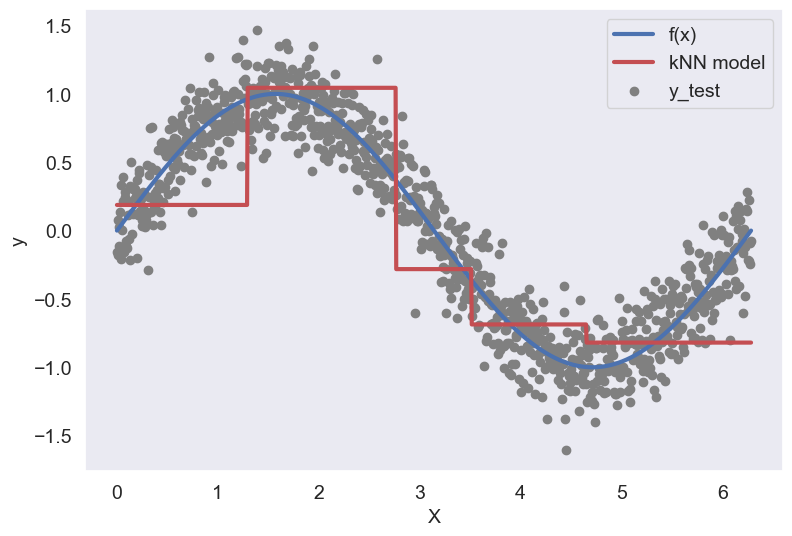

In [6]:
plt.figure(figsize=(9, 6))

plt.plot(X_test, f(X_test), label='f(x)', color='b', linewidth=3)
plt.plot(X_test, y_test_predict, label='kNN model', color='r', linewidth=3)
plt.scatter(X_test, y_test, label='y_test', color='0.5')

plt.xticks(size=14)
plt.xlabel("X", size=14)
plt.yticks(size=14)
plt.ylabel("y", size=14)
plt.legend(loc='best', fontsize=14)
plt.grid()
plt.show()

Строим график ошибок предсказания

In [7]:
errors = (y_test_predict - y_test)**2

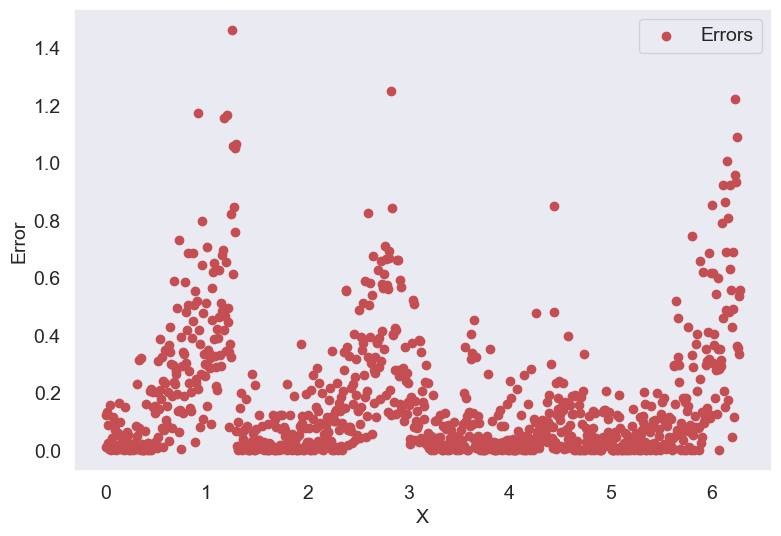

In [8]:
plt.figure(figsize=(9, 6))

plt.scatter(X_test, errors, label='Errors', color='r')

plt.xticks(size=14)
plt.xlabel("X", size=14)
plt.yticks(size=14)
plt.ylabel("Error", size=14)
plt.legend(loc='best', fontsize=14)
plt.grid()
plt.show()

## Несколько моделей

Обучаем несколько моделей на случайных обучающих выборках

In [9]:
N_iter = 1000
predictions = []
errors = []

for i in range(N_iter):

    # Генерируем случайную обучающую выборку
    X_train = np.random.random(size=5) * 2 * np.pi
    y_train = f(X_train) + np.random.normal(loc=0., scale=sigma, size=len(X_train))

    # Создаём модель
    reg = KNeighborsRegressor(n_neighbors=1)

    # Обучаем модель
    reg.fit(X_train.reshape(-1, 1), y_train)

    # Делаем предсказания
    y_test_predict = reg.predict(X_test.reshape(-1, 1))

    # Сохраняем предсказания
    predictions.append(y_test_predict)

    # Генерируем случайные значения y для тестовой выборки
    y_test_iter = f(X_test) + np.random.normal(loc=0., scale=sigma, size=len(X_test))

    # Вычисляем ошибки
    errors_iter = (y_test_predict - y_test_iter)**2

    # Сохраняем ошибки
    errors.append(errors_iter)

predictions = np.array(predictions)
errors = np.array(errors)

Оцениваем математическое ожидание предсказаний модели

In [10]:
y_test_predict_mean = predictions.mean(axis=0)

Строим графики моделей

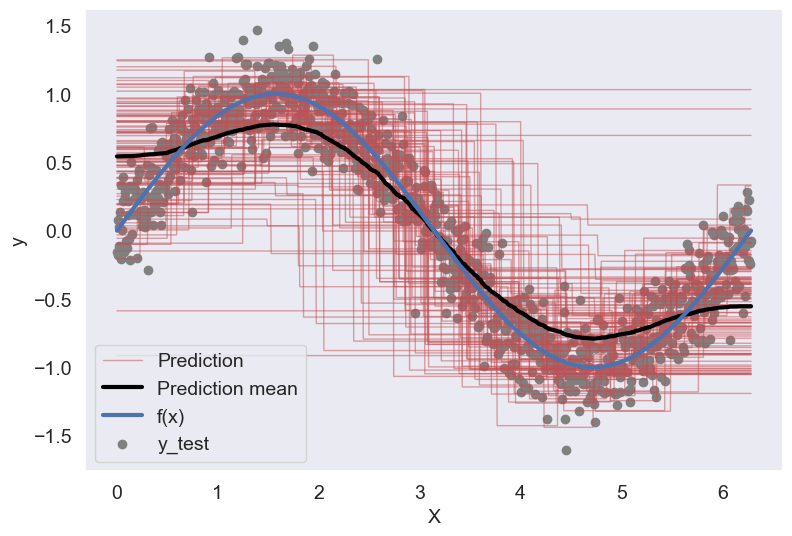

In [11]:
plt.figure(figsize=(9, 6))

for y_test_predict in predictions[:100]:
    plt.plot(X_test, y_test_predict, color='r', linewidth=1, alpha=0.5)

plt.plot(X_test, predictions[0], label='Prediction', color='r', linewidth=1, alpha=0.5)
plt.plot(X_test, y_test_predict_mean, label='Prediction mean', color='0', linewidth=3)
plt.plot(X_test, f(X_test), label='f(x)', color='b', linewidth=3)
plt.scatter(X_test, y_test, label='y_test', color='0.5')

plt.xticks(size=14)
plt.xlabel("X", size=14)
plt.yticks(size=14)
plt.ylabel("y", size=14)
plt.legend(loc='best', fontsize=14)
plt.grid()
plt.show()

### Разложение

\begin{equation}
\begin{split}
Error(x) & = \mathbb{E}_{X,\epsilon}\left[(a_X(x) - y(x))^2\right] = \\
      & = \mathbb{E}_{X}\left[(a_X(x) - \mathbb{E}_{X}[a_X(x)])^2\right]  + \left(\mathbb{E}_{X}\left[a_X(x)\right] - f(x)\right)^2 +  \sigma^2 = \\ & = \text{Variance}(x) + \text{Bias}^2(x)  + \text{Noise}
\end{split}
\end{equation}

In [12]:
# Вычисляем ожидаемые ошибки
error = errors.mean(axis=0)

# Вычисляем дисперсию (разброс) предсказаний модели
variance = predictions.std(axis=0)**2

# Вычисляем смещение модели
bias2 = (y_test_predict_mean - f(X_test))**2

# Вычисляем дисперсию шума
noise = sigma**2

composition = variance + bias2 + noise

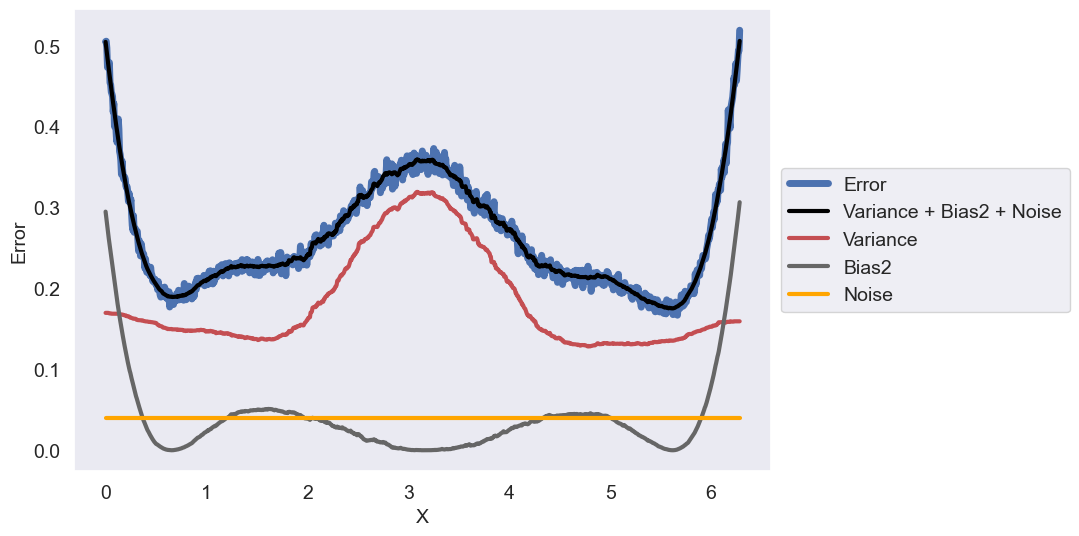

In [13]:
plt.figure(figsize=(9, 6))

plt.plot(X_test, error, label='Error', color='b', linewidth=5)
plt.plot(X_test, composition, label='Variance + Bias2 + Noise', color='0', linewidth=3)
plt.plot(X_test, variance, label='Variance', color='r', linewidth=3)
plt.plot(X_test, bias2, label='Bias2', color='0.4', linewidth=3)
plt.plot(X_test, [noise]*len(X_test), label='Noise', color='orange', linewidth=3)

plt.xticks(size=14)
plt.xlabel("X", size=14)
plt.yticks(size=14)
plt.ylabel("Error", size=14)
plt.legend(fontsize=14, loc='center left', bbox_to_anchor=(1, 0.5))
plt.grid()
plt.show()

## Бонус: теория
**Внимание!** Этот материал довольно сложный! [Здесь](https://github.com/esokolov/ml-course-hse/blob/master/2020-fall/seminars/sem08-bvd.pdf) есть хорошее объяснение (на русском).

Для простоты рассмотрим случай одномерной линейной регрессии.

**Алгоритм обучения**

В одномерной линейной регрессии зависимость между $y$ и $x$ моделируется простой линейной функцией $y = kx$. Оптимальный параметр $k$ находится на обучающей выборке $X = \{(x_1, y_1), \dots (x_\ell, y_\ell)\}$ минимизацией $\text{MSE}= \sum_{i=1}^\ell (y_i - k x_i)^2$.

В результате получаем следующий алгоритм $\mu(X)$:
    $$
    \mu(X)(x) = k(X ) x, \quad k(X) = \frac{\sum_i x_i y_i}{\sum_i x_i^2}.
    $$

**Модель порождения данных**

Предположим, что $x$ порождается из нормального распределения:
$$x \sim p(x) = \mathcal{N}(0, \sigma_1^2).$$

Истинная метка $x$ задаётся некоторой функцией с шумом:
$$f(x): y = f(x) + \varepsilon,$$
$$\varepsilon \sim p(\varepsilon) = \mathcal{N}(0, \sigma_2^2)$$

Иными словами:
$$y \sim p(y|x) = \mathcal{N}(f(x), \sigma_2^2)$$
    
 Выборка $X$ состоит из $\ell$ независимых пар $(x_i, y_i)$.

**Задача 1.1** Найдите компоненту шума для одномерной линейной регрессии.

**Решение**  

$p(y|x)$ — нормальное распределение, поэтому для него легко найти математическое ожидание:
    $$
    \mathbb{E}[y|x] = f(x).
    $$

  Следовательно:

$$
    \mathbb{E}_{x, y}\bigl[(y - \mathbb{E}[y|x] )^2\bigr] =
    \mathbb{E}_{x, \varepsilon}\bigl[(f(x) + \varepsilon - f(x) )^2\bigr] =
    \mathbb{E}_{\varepsilon} \varepsilon^2 = \mathbb{D}\varepsilon + \bigl(\mathbb{E}\varepsilon\bigr)^2 = \sigma_2^2 + 0 = \sigma_2^2.
$$


    

    
**Задача 1.2**

Найдите компоненту смещения для одномерной линейной регрессии при $f(x) = ax$.  

**Решение:**

Для начала найдём ответ алгоритма на $x$, «усреднённый по всем выборкам»:

$$
    	\mathbb{E}_{X}[\mu(X)(x)] = \mathbb{E}_{X}[k(X)] \, x.
$$
        
Нужно найти «средний» $k$ по всем выборкам:

$$ \mathbb{E}_{X}[k(X)] = \int \frac{\sum_i x_i (f(x_i)+\varepsilon_i)}{\sum_i x_i^2} \prod_i \bigl( p(x_i) p(\varepsilon_i) \bigr)  dx_1 \dots dx_\ell \, d\varepsilon_1 \dots d\varepsilon_\ell.
$$
Это несобственный интеграл, который не всегда удаётся вычислить аналитически.

Однако в случае линейной зависимости получаем:
    	$$
    	\mathbb{E}_{X}[k(X)] =  \int \frac{\sum_i x_i (a\,x_i+\varepsilon_i)}{\sum_i x_i^2}  p(\bar x) p(\bar \varepsilon)  d \bar x d \bar \varepsilon =
    	$$
        ...
    	$$
    	=a \int \frac{\sum_i x_i^2}{\sum_i x_i^2}  p(\bar x)  p(\bar \varepsilon)  d \bar x d \bar \varepsilon +
    	\int \frac{\sum_i x_i \varepsilon_i}{\sum_i x_i^2}  p(\bar x)  p(\bar \varepsilon)  d \bar x d \bar \varepsilon.
    	$$
Первый интеграл равен $a$ (как интеграл от плотности по всему пространству). Второй интеграл равен нулю: при фиксированных $x_1, \dots, x_\ell$ подынтегральное выражение линейно по $\varepsilon_i$, а $\mathbb{E}\varepsilon_i = 0$ и шум не зависит от $x$ (для симметричной плотности $p(\varepsilon)$ это равносильно тому, что подынтегральная функция нечётна по $\bar\varepsilon$). Таким образом, «средний» коэффициент равен $a$.

*Замечание.* Это верно при $\ell \ge 2$. При $\ell = 1$ имеем $k = a + \varepsilon_1 / x_1$, а отношение двух независимых центрированных нормальных величин имеет распределение Коши, у которого нет математического ожидания: второй интеграл расходится.

Найдём компоненту смещения:
  $$
    	\mathbb{E}_{x}\bigl[(\mathbb{E}_{X}[\mu(X)(x)] - \mathbb{E}[y|x] )^2\bigr] = \mathbb{E}_{x}\bigl[(a x -  a x )^2\bigr] = 0.
  $$

Этот результат вполне интуитивен: если перебрать все возможные выборки длины $\ell$ и усреднить значение $k$, мы получим истинное значение коэффициента.



**Задача 1.3** Найдите компоненту разброса для одномерной линейной регрессии при $f(x) = ax$.  

$$
    	\mathbb{E}_{x}\bigl[\mathbb{E}_{X}\bigl[(\mu(X)(x) - \mathbb{E}_{X}[\mu(X)(x)] )^2\bigr]\bigr] =
    	\mathbb{E}_{x}\bigl[\mathbb{E}_{X}\bigl[(
    	a x +  \frac{\sum_i x_i \varepsilon_i}{\sum_i x_i^2} x - ax
    	 )^2\bigr]\bigr]  =\biggl( \mathbb{E}_{x} x^2 \biggr)
    	 \biggl (\mathbb{E}_{X}\biggl(
    	 \frac{\sum_i x_i \varepsilon_i}{\sum_i x_i^2}
    	\biggr )^2\biggr) =
$$
      
$$=\sigma_1^2\mathbb{E}_{X}\biggl (\frac{\sum_i x_i \varepsilon_i}{\sum_i x_i^2} \biggr)^2.
$$

Упростим математическое ожидание:

$$
    	\mathbb{E}_{X}\biggl(
    	\frac{\sum_i x_i \varepsilon_i}{\sum_i x_i^2}
    	\biggr )^2 = \mathbb{E}_{\bar x} \biggl[ \frac {\sum_{i \ne j} x_i x_j \mathbb{E}_{\bar \varepsilon } [\varepsilon_i \varepsilon_j] +
    		\sum_i x_i^2 \mathbb{E}_{\bar \varepsilon } \varepsilon_i^2 } {(\sum_i x_i^2)^2}
    	 \biggr].
$$

Поскольку $\varepsilon_i$ и $\varepsilon_j$ независимы, $\mathbb{E}[\varepsilon_i \varepsilon_j] = 0$, а $\mathbb{E}_{\bar \varepsilon } \varepsilon_i^2 = \sigma_2^2$.

Тогда

$$
    	\mathbb{E}_{X}\biggl(
    	\frac{\sum_i x_i \varepsilon_i}{\sum_i x_i^2}
    	\biggr )^2 = \mathbb{E}_{\bar x} \biggl[ \frac {
    		\sum_i x_i^2 \sigma_2^2} {(\sum_i x_i^2)^2}
    	\biggr] = \sigma_2^2 \mathbb{E}_{\bar x} \biggl[ \frac 1 {\sum_i x_i^2} \biggr],
$$

и разброс равен:
$$
    	\mathbb{E}_{x}\bigl[\mathbb{E}_{X}\bigl[(\mu(X)(x) - \mathbb{E}_{X}[\mu(X)(x)] )^2\bigr]\bigr] =
    	 \sigma_1^2 \sigma_2^2
    	\mathbb{E}_{\bar x} \biggl[ \frac 1 {\sum_i x_i^2} \biggr].
$$

Осталось вычислить $\mathbb{E}_{\bar x} \bigl[ 1 / \sum_i x_i^2 \bigr]$. Так как $x_i \sim \mathcal{N}(0, \sigma_1^2)$ независимы, $\sum_i x_i^2 = \sigma_1^2 \xi$, где $\xi \sim \chi^2_\ell$, а $\mathbb{E}[1/\xi] = \frac{1}{\ell - 2}$ при $\ell > 2$. Получаем

$$
\text{Variance} = \sigma_1^2 \sigma_2^2 \cdot \frac{1}{\sigma_1^2 (\ell - 2)} = \frac{\sigma_2^2}{\ell - 2}, \quad \ell > 2.
$$

При $\ell \le 2$ это математическое ожидание бесконечно, т.е. разброс бесконечен. Заметим, что ответ не зависит от $\sigma_1$ и убывает примерно как $1/\ell$ с ростом размера выборки.

# 2. Ансамбли

### Данные — датасет Titanic

Сегодня мы будем работать с датасетом Titanic.

In [14]:
data = pd.read_csv('titanic.csv')
#data = pd.read_csv('https://grantmlong.com/data/titanic.csv')
cols_2_drop = ['PassengerId', 'Ticket', 'Cabin', 'Name']
data = data.drop(cols_2_drop, axis=1)
data.loc[:, 'Age'] = data.Age.fillna(-999)
data = data.dropna()
data.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S


## Mean label encoding (кодирование средним значением таргета)

У нас есть две категориальные переменные: `Sex` и `Embarked`.

Сегодня для их кодирования мы используем новую технику: **mean label encoding**.

Идея **mean label encoding**: каждое уникальное значение категориального признака кодируется **на основе доли положительного класса в целевой переменной**.

**Будьте осторожны!**

Поскольку мы кодируем признак на основе классов целевой переменной, это может привести к утечке данных (data leakage) и переобучению. Чтобы этого избежать, mean encoding обычно применяют вместе с той или иной регуляризацией.

Минимальное обязательное требование — считать средние **только по обучающей выборке** и затем применять их к тестовой. Поэтому сначала разобьём данные на train и test. (В sklearn ≥ 1.3 есть готовый `TargetEncoder`, который дополнительно использует кросс-фиттинг внутри обучающей выборки.)

Подробнее можно почитать [здесь](https://towardsdatascience.com/why-you-should-try-mean-encoding-17057262cd0).


Разбиваем данные на обучающую и тестовую выборки **до** кодирования.

In [15]:
X = data.drop('Survived', axis=1)
Y = data['Survived']
# Разбиение на обучающую и тестовую выборки — ДО кодирования, чтобы не было утечки таргета
train_X, test_X, train_Y, test_Y = train_test_split(X, Y, test_size=0.2, random_state=42)
train_X, test_X = train_X.copy(), test_X.copy()
train_X.shape, test_X.shape, train_Y.shape, test_Y.shape

((711, 7), (178, 7), (711,), (178,))

**Mean label encoding** для переменной Sex (средние считаем только по обучающей выборке).

In [16]:
mean_sex = train_Y.groupby(train_X['Sex']).mean()
# доля положительного класса в целевой переменной (только по train)
mean_sex

Sex
female    0.744770
male      0.197034
Name: Survived, dtype: float64

In [17]:
train_X['Sex'] = train_X['Sex'].map(mean_sex)
test_X['Sex'] = test_X['Sex'].map(mean_sex)

**Mean label encoding** для переменной Embarked (тоже только по обучающей выборке).

In [18]:
mean_emb = train_Y.groupby(train_X['Embarked']).mean()
train_X['Embarked'] = train_X['Embarked'].map(mean_emb)
test_X['Embarked'] = test_X['Embarked'].map(mean_emb)
train_X.head()

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
708,1,0.744770,22.0,0,0,151.5500,0.334630
240,3,0.744770,-999.0,1,0,14.4542,0.560606
382,3,0.197034,32.0,0,0,7.9250,0.334630
792,3,0.744770,-999.0,8,2,69.5500,0.334630
683,3,0.197034,14.0,5,2,46.9000,0.334630


## Напоминание: высокий разброс решающих деревьев

Говорят, что у решающих деревьев **высокий разброс** (high variance). Небольшие изменения в данных могут приводить к радикально разным деревьям.

In [19]:
# Рисуем дерево средствами sklearn — не требует установленного в системе Graphviz
def plot_tree(model, X, max_depth=None):
    sk_plot_tree(model, feature_names=list(X.columns), filled=True, rounded=True, max_depth=max_depth, fontsize=10)

In [20]:
# Обучаем два дерева на двух разных случайных подвыборках (80%) одной и той же обучающей выборки,
# а качество обоих оцениваем на ОДНОЙ и той же тестовой выборке
train_X_1, _, train_Y_1, _ = train_test_split(train_X, train_Y, train_size=0.8, random_state=2)
train_X_2, _, train_Y_2, _ = train_test_split(train_X, train_Y, train_size=0.8, random_state=7)

# random_state влияет на порядок, в котором рассматриваются признаки. При каждом разбиении признаки случайно перемешиваются
tree1 = DecisionTreeClassifier(random_state=0, max_depth=3)
tree1.fit(train_X_1, train_Y_1)
tree1_accuracy = accuracy_score(test_Y, tree1.predict(test_X))
print(f'Accuracy первого дерева: {tree1_accuracy:.4f}')

tree2 = DecisionTreeClassifier(random_state=0, max_depth=3)
tree2.fit(train_X_2, train_Y_2)

tree2_accuracy = accuracy_score(test_Y, tree2.predict(test_X))

print(f'Accuracy второго дерева: {tree2_accuracy:.4f}')

Accuracy первого дерева: 0.8034
Accuracy второго дерева: 0.8090


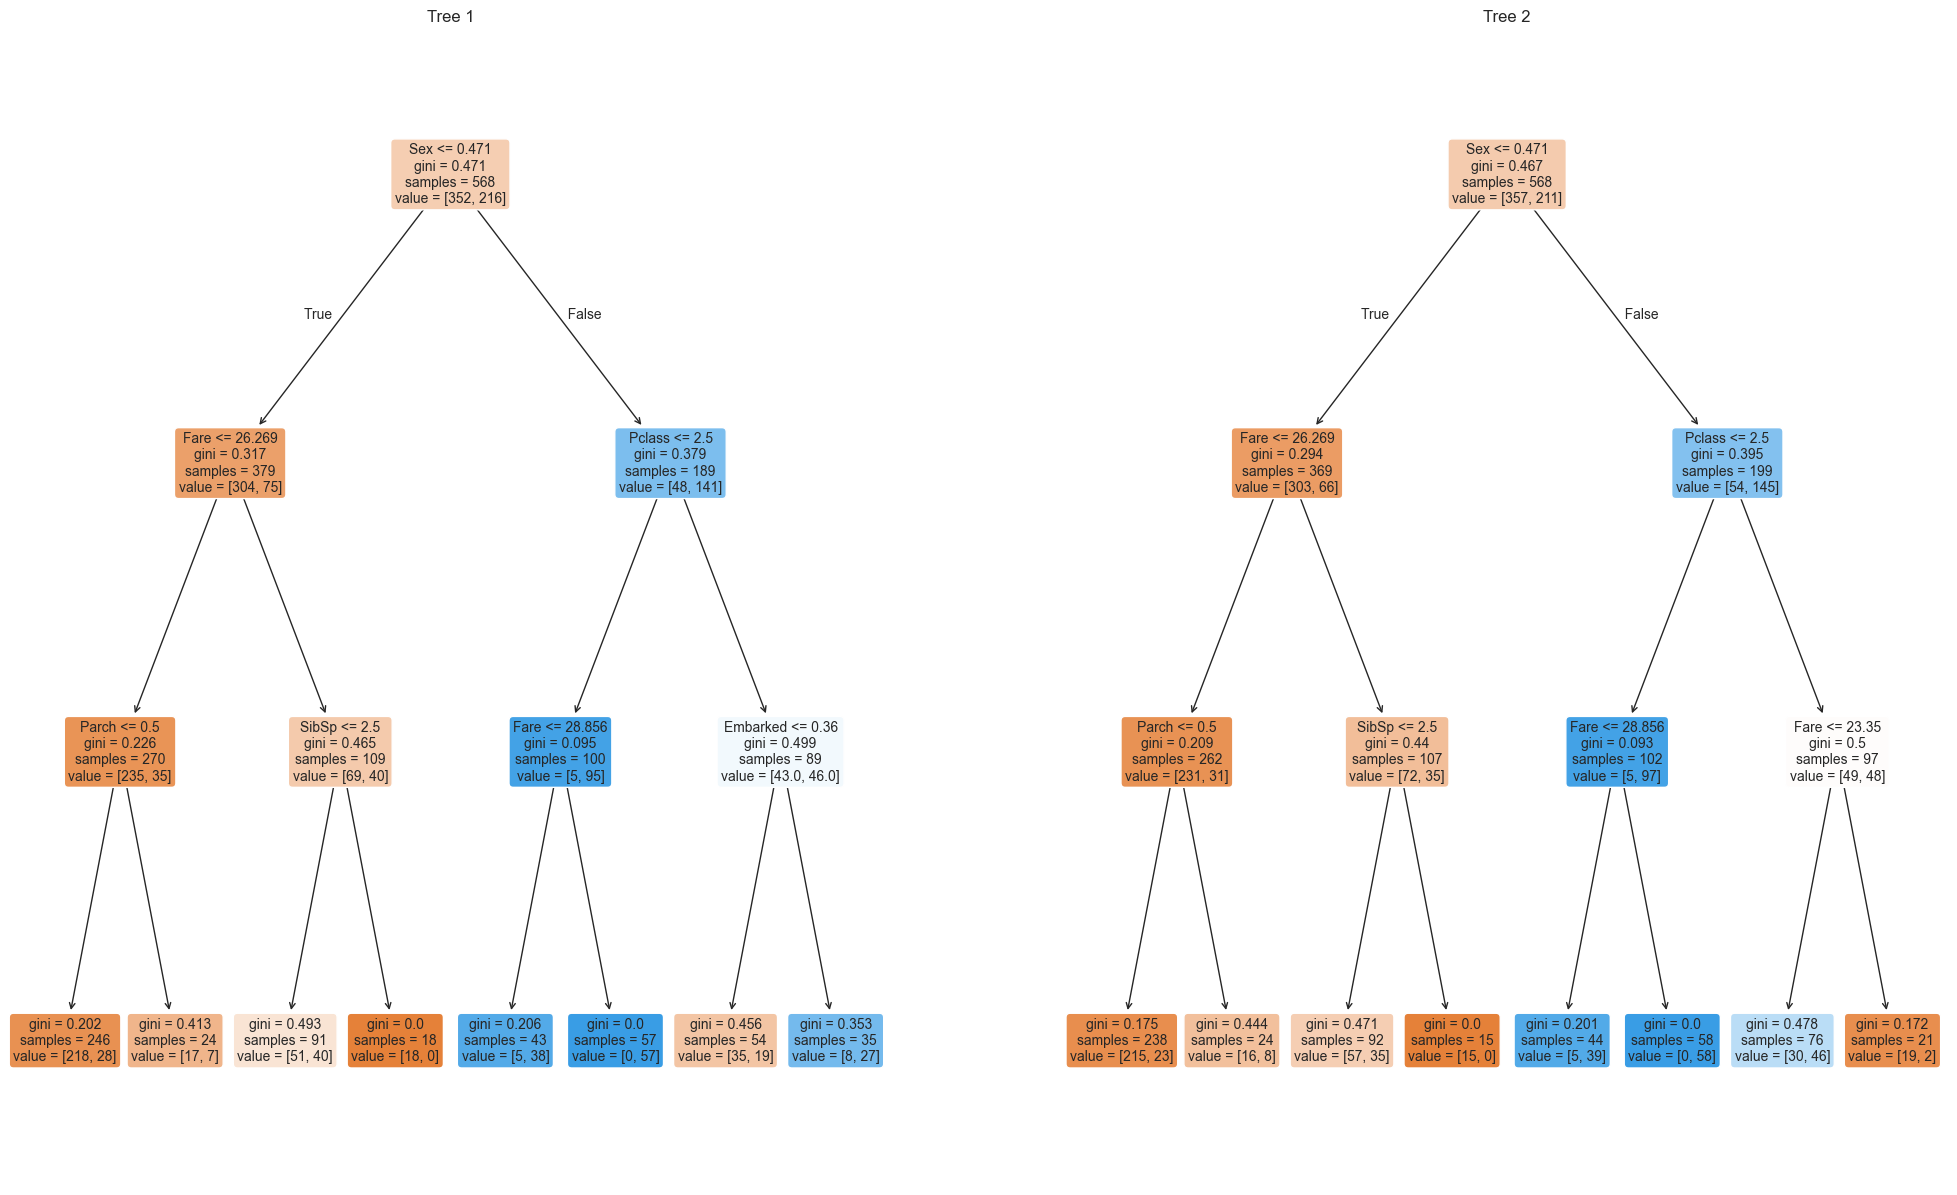

In [21]:
plt.figure(figsize=(25, 15))
plt.subplot(1, 2, 1)
plot_tree(tree1, train_X)
plt.axis('off')
plt.title(f'Tree 1')
plt.subplot(1, 2, 2)
plot_tree(tree2, train_X_2)
plt.axis('off')
plt.title(f'Tree 2')
plt.show()

Оба дерева обучены на подвыборках одной и той же обучающей выборки и проверены на одной и той же тестовой выборке, но получаются разными (сравните, например, правые поддеревья) и показывают разные результаты.

С более глубокими деревьями всё становится только хуже. Обучим по 100 деревьев разной глубины на бутстрэп-выборках из обучающей выборки и посмотрим, как часто два случайно выбранных дерева дают разные ответы на тестовых объектах:

In [22]:
rng = np.random.RandomState(0)
for depth in [1, 3, 5, None]:
    preds = []
    for b in range(100):
        idx = rng.randint(0, len(train_X), len(train_X))  # бутстрэп-выборка
        tree = DecisionTreeClassifier(random_state=0, max_depth=depth).fit(train_X.iloc[idx], train_Y.iloc[idx])
        preds.append(tree.predict(test_X))
    p = np.mean(preds, axis=0)  # доля деревьев, предсказавших класс 1, для каждого тестового объекта
    # 2p(1-p) — вероятность, что два случайных дерева разойдутся на объекте
    print(f'max_depth={depth}: два случайных дерева расходятся в среднем на {np.mean(2 * p * (1 - p)):.1%} тестовых объектов')

max_depth=1: два случайных дерева расходятся в среднем на 0.0% тестовых объектов
max_depth=3: два случайных дерева расходятся в среднем на 8.8% тестовых объектов
max_depth=5: два случайных дерева расходятся в среднем на 12.7% тестовых объектов
max_depth=None: два случайных дерева расходятся в среднем на 17.7% тестовых объектов


## Бэггинг решающих деревьев (Bootstrap aggregated Decision Trees)
Вместо того чтобы обучать одно дерево, сделаем следующее:
1. Сгенерируем из обучающей выборки $B$ бутстрэп-выборок (выборок с возвращением, помните?).
2. На каждой обучим (глубокое) решающее дерево и получим $B$ деревьев $f_1, f_2, \dots, f_B$
3. Для предсказания усредним предсказания всех деревьев: $\hat{y} = 1/B \sum_{i=1}^{B} f_i(x)$

В задаче классификации `BaggingClassifier` усредняет предсказанные деревьями вероятности классов (`predict_proba`) и выбирает класс с наибольшей средней вероятностью. Если базовая модель не умеет предсказывать вероятности, используется голосование большинством.


In [23]:
# Бэггинг (BaggingClassifier / BaggingRegressor) можно использовать с любой моделью, не только с решающими деревьями
# Бэггинг уменьшает разброс, но не смещение, поэтому базовые деревья берём глубокими (низкое смещение, высокий разброс)

model = BaggingClassifier(estimator=DecisionTreeClassifier(max_depth=None), n_jobs=-1, n_estimators=100, random_state=42)
model.fit(train_X, train_Y)

BaggingClassifier(estimator=DecisionTreeClassifier(), n_estimators=100,
                  n_jobs=-1, random_state=42)

In [24]:
print(f'Accuracy бэггинга деревьев: {accuracy_score(test_Y, model.predict(test_X)):.4f}')


Accuracy бэггинга деревьев: 0.7865


Можно получить доступ к отдельным деревьям. Деревья глубокие, поэтому рисуем только их первые 3 уровня.

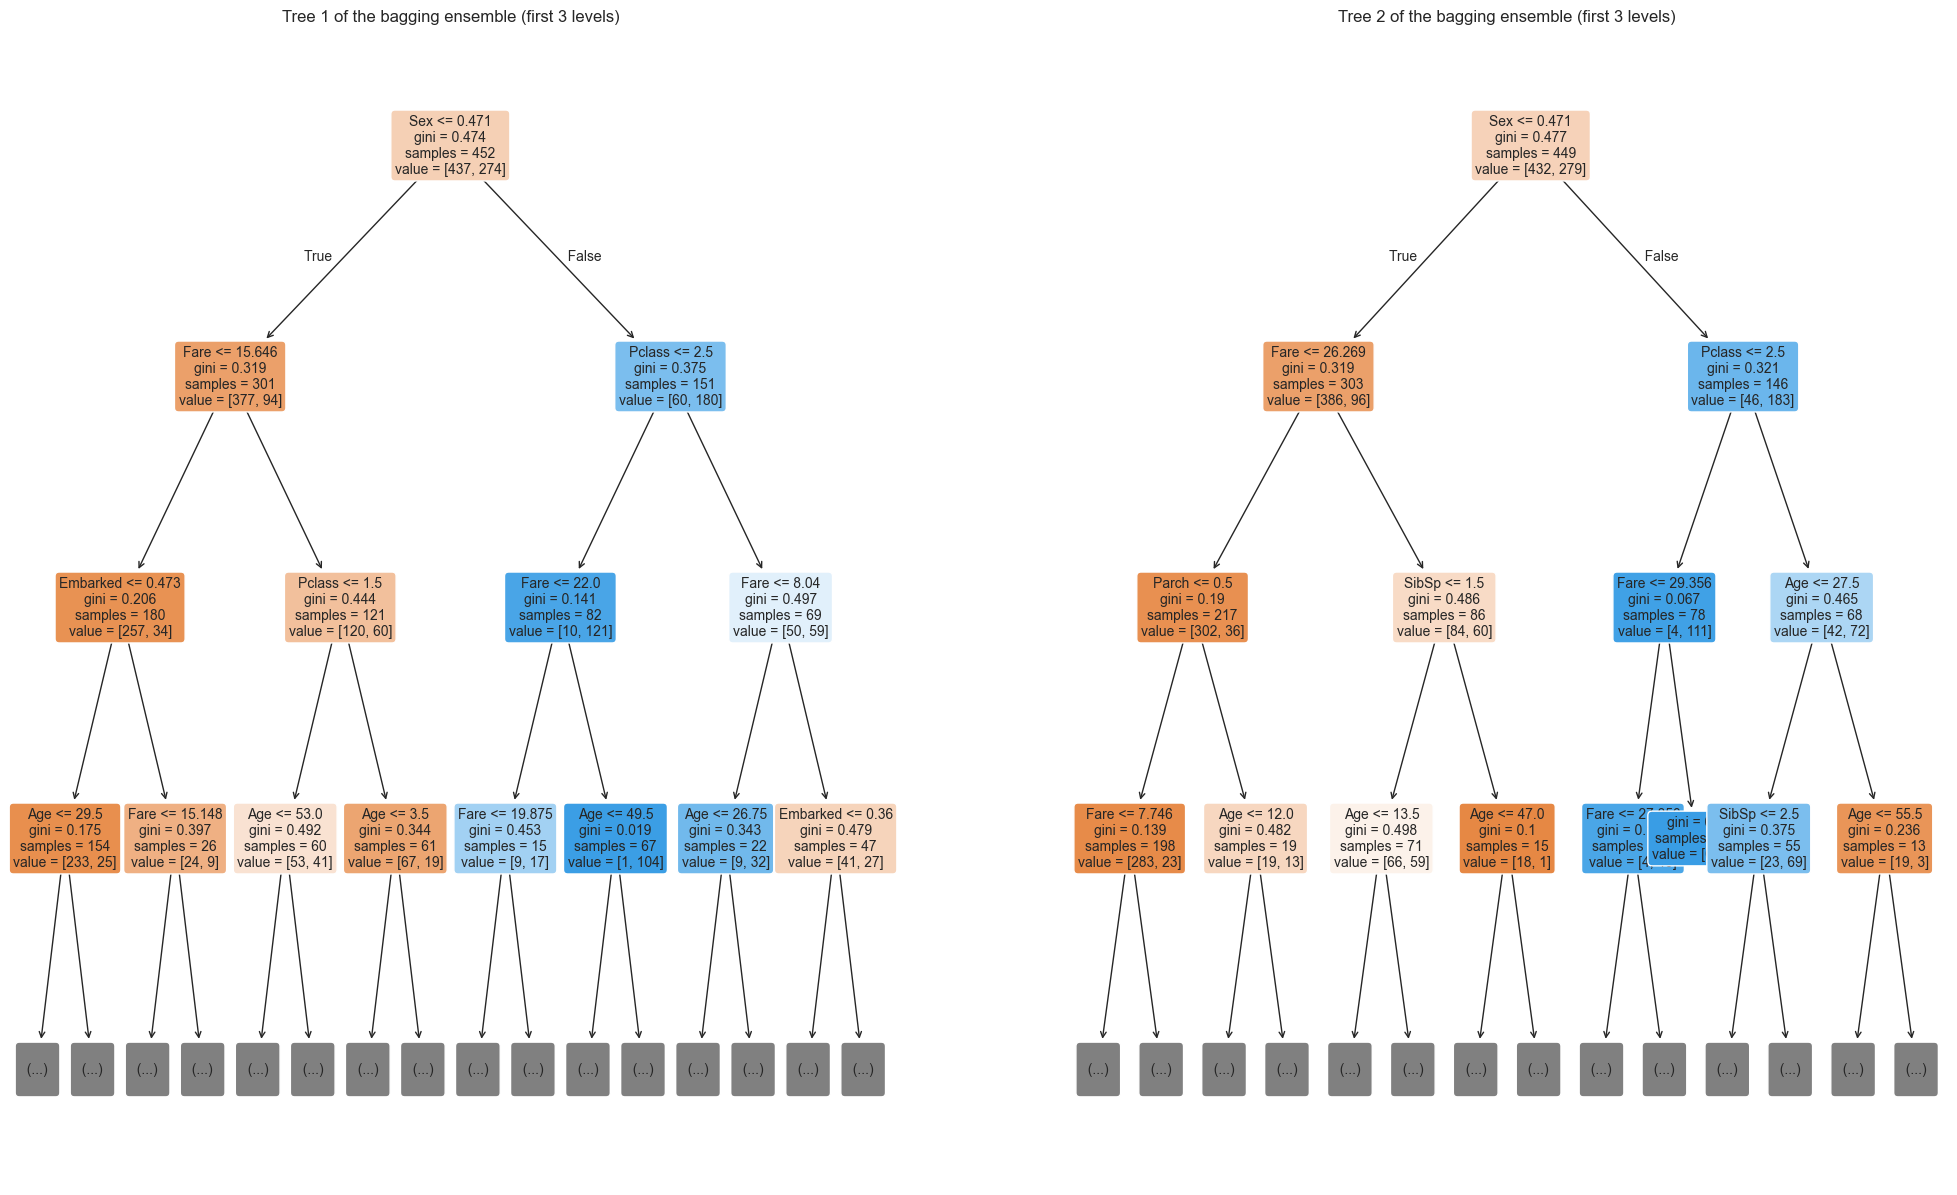

In [25]:
tree1, tree2 = model.estimators_[0], model.estimators_[1]

plt.figure(figsize=(25, 15))
plt.subplot(1, 2, 1)
plot_tree(tree1, train_X, max_depth=3)
plt.axis('off')
plt.title(f'Tree 1 of the bagging ensemble (first 3 levels)')
plt.subplot(1, 2, 2)
plot_tree(tree2, train_X, max_depth=3)
plt.axis('off')
plt.title(f'Tree 2 of the bagging ensemble (first 3 levels)')
plt.show()

Процесс обучения бэггинг-ансамбля позволяет оценить ошибку на тесте **без кросс-валидации**!

Каждое дерево обучается на бутстрэп-выборке из обучающей выборки. Конкретный объект не попадает в бутстрэп-выборку размера $n$ с вероятностью $(1 - 1/n)^n \approx 1/e \approx 36.8\%$, т.е. каждый объект является *out-of-bag* (OOB) примерно для трети деревьев.

Для каждого объекта $x_i$ можно сделать предсказания с помощью тех деревьев, в обучающую выборку которых $x_i$ не попал. Затем эти предсказания можно усреднить и использовать для вычисления ошибки. Это будет честная оценка качества на новых данных, не требующая отдельной валидационной выборки.

In [26]:
model = BaggingClassifier(estimator=DecisionTreeClassifier(max_depth=None), n_jobs=-1, n_estimators=20, oob_score=True, random_state=42)
model.fit(train_X, train_Y)

BaggingClassifier(estimator=DecisionTreeClassifier(), n_estimators=20,
                  n_jobs=-1, oob_score=True, random_state=42)

In [27]:
print(f'Оценка качества на тесте по out-of-bag: {model.oob_score_:.4f}')
print(f'Оценка качества на тесте с помощью кросс-валидации: {cross_val_score(model, train_X, train_Y, scoring="accuracy").mean():.4f}')
print(f'Реальное качество на тесте: {accuracy_score(test_Y, model.predict(test_X)):.4f}')

Оценка качества на тесте по out-of-bag: 0.8200
Оценка качества на тесте с помощью кросс-валидации: 0.8116
Реальное качество на тесте: 0.7584


OOB, кросс-валидация и отложенная выборка дают близкие, но не совпадающие оценки. Тестовая выборка маленькая (178 объектов), поэтому стандартная ошибка accuracy на ней $\approx \sqrt{p(1-p)/n} \approx \sqrt{0.8 \cdot 0.2 / 178} \approx 0.03$. Расхождения в пределах двух стандартных ошибок (до $\approx 0.06$) вполне объясняются шумом оценки на маленькой тестовой выборке, а не ошибкой OOB.

## Случайный лес (Random Forest)

Деревья в бэггинг-ансамблях, как правило, *скоррелированы* — они получаются очень похожими. Если агрегировать предсказания многих похожих деревьев, разброс уменьшается не сильно.

Как сделать деревья менее скоррелированными?

**Решение Random Forest**: каждый раз при выборе разбиения **случайно выбираем $m$ признаков** из общего числа $p$, где $m < p$, и **ищем лучшее разбиение только по этим $m$ признакам**.

In [28]:
model = RandomForestClassifier(n_estimators=100, n_jobs=-1, max_depth = 3, oob_score=True, random_state=42)
model.fit(train_X, train_Y)

RandomForestClassifier(max_depth=3, n_jobs=-1, oob_score=True, random_state=42)

In [29]:
print(f'Оценка качества на тесте по out-of-bag: {model.oob_score_:.4f}')
print(f'Реальное качество на тесте: {accuracy_score(test_Y, model.predict(test_X)):.4f}')

Оценка качества на тесте по out-of-bag: 0.8017
Реальное качество на тесте: 0.7978


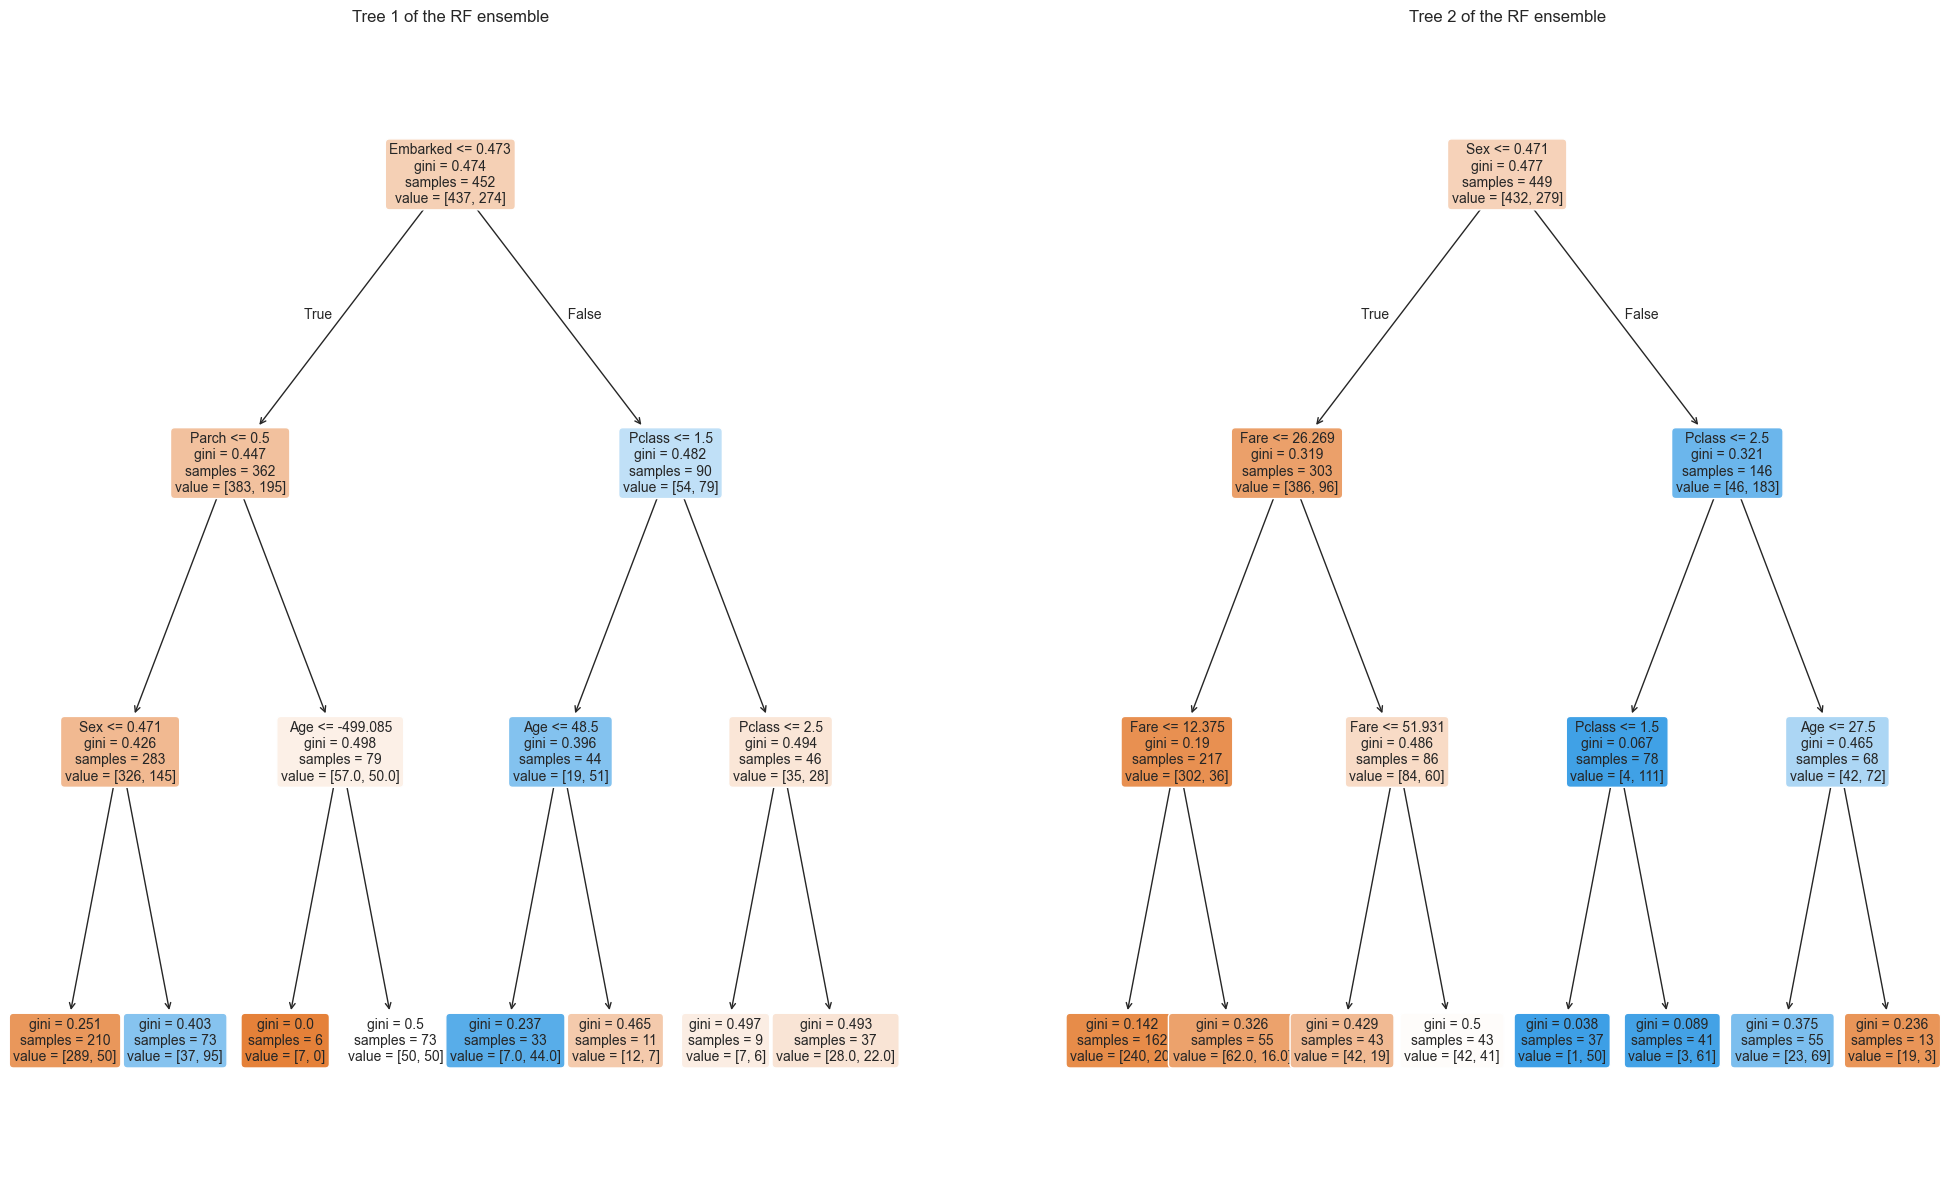

In [30]:
tree1, tree2 = model.estimators_[0], model.estimators_[1]

plt.figure(figsize=(25, 15))
plt.subplot(1, 2, 1)
plot_tree(tree1, train_X)
plt.axis('off')
plt.title(f'Tree 1 of the RF ensemble')
plt.subplot(1, 2, 2)
plot_tree(tree2, train_X)
plt.axis('off')
plt.title(f'Tree 2 of the RF ensemble')
plt.show()

In [31]:
# Теперь попробуем реалистичное значение max_depth
model = RandomForestClassifier(n_estimators=100, n_jobs=-1, max_depth = None, oob_score=True, random_state=42)
model.fit(train_X, train_Y)
print(f'Оценка качества на тесте по out-of-bag: {model.oob_score_:.4f}')
print(f'Реальное качество на тесте: {accuracy_score(test_Y, model.predict(test_X)):.4f}')


Оценка качества на тесте по out-of-bag: 0.8186
Реальное качество на тесте: 0.7697


## Важность признаков

В sklearn `feature_importances_` вычисляется методом **MDI** (Mean Decrease in Impurity): в каждом дереве для признака суммируется уменьшение критерия неоднородности (по умолчанию — индекса Джини, а не энтропии), взвешенное на долю объектов в узле, по всем узлам, где разбиение идёт по этому признаку. Важности нормируются внутри каждого дерева и затем усредняются по всем деревьям.

**Осторожно:** MDI считается по обучающей выборке и завышает важность признаков с большим числом уникальных значений (здесь это `Age` и `Fare`). Более надёжная альтернатива — **permutation importance** на тестовой выборке: насколько падает качество, если случайно перемешать значения признака.

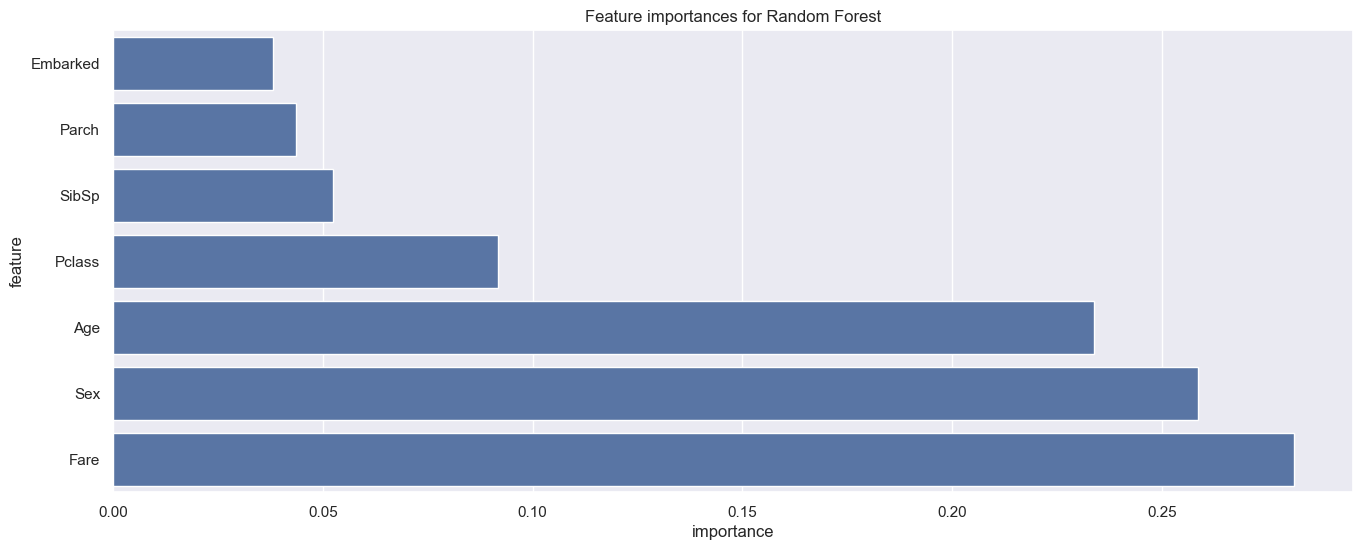

In [32]:
feature_importances = zip(train_X.columns, model.feature_importances_)
feature_importances = sorted(feature_importances, key=lambda x: x[1])
feature_importances = pd.DataFrame(feature_importances, columns=['feature', 'importance'])

plt.title('Feature importances for Random Forest')
sns.barplot(x='importance', y='feature', data=feature_importances)
plt.show()

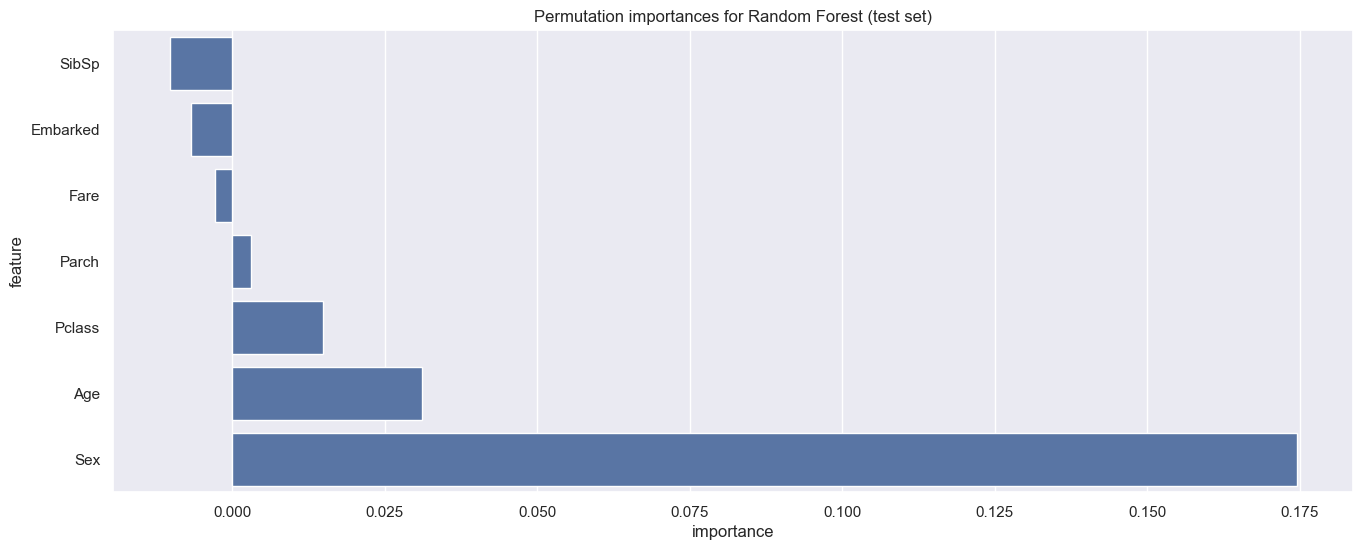

In [33]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(model, test_X, test_Y, scoring='accuracy', n_repeats=30, random_state=42, n_jobs=-1)
perm_importances = pd.DataFrame({'feature': test_X.columns, 'importance': perm.importances_mean}).sort_values('importance')

plt.title('Permutation importances for Random Forest (test set)')
sns.barplot(x='importance', y='feature', data=perm_importances)
plt.show()

## Настройка гиперпараметров

Основные параметры, которые стоит настраивать у этой модели:
* `n_estimators` — число деревьев,
* `max_samples` — число объектов в бутстрэп-выборке,
* `max_features` — число признаков, рассматриваемых при разбиении,
* `max_depth` — максимальная глубина деревьев.
Обычно её советуют не ограничивать, но задать `max_depth` бывает полезно, если нужно ускорить алгоритм на больших данных или если в данных много шума.


Подробнее [здесь](https://dyakonov.org/2016/11/14/%D1%81%D0%BB%D1%83%D1%87%D0%B0%D0%B9%D0%BD%D1%8B%D0%B9-%D0%BB%D0%B5%D1%81-random-forest/).

In [34]:
parameters = {'n_estimators': [5,10,50, 100, 500], 'max_features' : [None, 3], 'max_depth':[None, 3, 5, 10]}

model = RandomForestClassifier(random_state=42)
clf = GridSearchCV(model, parameters, scoring = 'accuracy', cv = 5)

clf.fit(train_X, train_Y)
pred = clf.predict(test_X)

print('Лучшие параметры: ', clf.best_params_)

Лучшие параметры:  {'max_depth': 10, 'max_features': None, 'n_estimators': 500}


Помимо регрессии и классификации, случайный лес (и ансамбли случайных деревьев вообще) можно использовать также для:
* **кластеризации** — через матрицу близостей (proximity): два объекта близки, если часто попадают в один и тот же лист; по этой матрице можно кластеризовать объекты (в том числе без учителя — unsupervised RF);
* **обнаружения аномалий** — объекты с малой близостью к остальным подозрительны (Breiman); на практике чаще используют отдельный алгоритм на случайных деревьях — Isolation Forest (`sklearn.ensemble.IsolationForest`);
* **снижения размерности и визуализации** — например, MDS по proximity-матрице; близкий по духу `RandomTreesEmbedding` кодирует объект номерами листьев, но это скорее нелинейное преобразование признаков, чем снижение размерности;
* **отбора признаков** — по важностям признаков (например, `sklearn.feature_selection.SelectFromModel`).

И, возможно, не только!